# Module: Loading spectral library

> Loading simple stellar population (SSP) flux lines. Also loading the metallicity and age grids that the flux lines are computed on. 

In [ ]:
#| default_exp load_sps_library

In [ ]:
#| hide
from nbdev.showdoc import *

In [ ]:
#| export
import numpy as np
import os
import matplotlib.pylab as plt
from watercolor.load_sim_stellar_catalog import Z_SOLAR_PADOVA, H0
from importlib.resources import files as _pkg_files

In [ ]:
#| hide

# dataPath = pkg_resources.resource_stream("watercolor", "data/sps_library_data/log_age.npy")
# dataPath.name


In [ ]:
#| export

STELLAR_LIBRARY_DIR = "data/sps_library_data/"
LIBRARY_FLUX_FILE = str(_pkg_files("watercolor").joinpath(STELLAR_LIBRARY_DIR, "ssp_spec_flux_lines.npy"))
LIBRARY_WAVE_FILE = str(_pkg_files("watercolor").joinpath(STELLAR_LIBRARY_DIR, "ssp_spec_wave.npy"))
LIBRARY_AGE_FILE = str(_pkg_files("watercolor").joinpath(STELLAR_LIBRARY_DIR, "log_age.npy"))
LIBRARY_METAL_FILE = str(_pkg_files("watercolor").joinpath(STELLAR_LIBRARY_DIR, "zlegend.npy"))

In [ ]:
#| export

C_ANGSTROM_PER_S = 2.99792458e18 # Speed of light in Angstrom/s

def load_fsps_spectral_library(flux_fileIn:str=LIBRARY_FLUX_FILE, # Input flux file of the stellar spectra library
                               wave_fileIn:str=LIBRARY_WAVE_FILE, # Input wavelength file of the stellar spectra library
                               per_angstrom:bool=True, # Convert the stored L_nu [Lsun/Hz] to L_lambda [Lsun/A]
                              ) -> tuple: #Fluxes (Lsun/A per Msun formed), wavelengths (A)
    '''
    Load the SSP spectral library.

    The bundled `ssp_spec_flux_lines.npy` is the native FSPS output
    (Padova isochrones + BaSeL, Kroupa IMF, nebular emission on): **L_nu in
    Lsun/Hz per 1 Msun of stars formed** -- checked against python-fsps
    (`StellarPopulation.get_spectrum(peraa=False)`), ratio 1.000 over the
    whole grid. Everything downstream (CSP sums, bolometric integrals over
    wavelength, the redshift/dimming step, dust) works in L_lambda, so convert
    here, once: L_lambda = L_nu * c / lambda^2. Reading the stored numbers as
    Lsun/A instead tilts every SED by lambda^2 (far too red: +0.6 in u-g,
    +1.0 in g-i) and leaves it ~1e10x too faint.
    '''
    spec_flux = np.load(flux_fileIn)
    spec_wave = np.load(wave_fileIn)
    if per_angstrom:
        spec_flux = spec_flux * C_ANGSTROM_PER_S / spec_wave**2
    return spec_flux, spec_wave

In [ ]:
#| export
def _load_fsps_age(age_fileIn:str=LIBRARY_AGE_FILE # Input age file of the stellar spectra library 
                  )-> np.array: # Age in Gyr
    
    # log_age.npy stores log10(age) in years; subtracting 9 converts to log10(age/Gyr)
    log_age_gyr = np.load( age_fileIn ) - 9
    age_fsps_gyr = 10**log_age_gyr  # Gyr
    return age_fsps_gyr

In [ ]:
#| export
def _load_fsps_metallicity(metal_fileIn:str=LIBRARY_METAL_FILE, # Input metallicity file of the stellar spectra library
                           Z_solar:np.float32=Z_SOLAR_PADOVA # Solar metallicity in Padova
                          ) -> np.array: #Metallicity values in Z/Z_solar units
    Z_legend = np.load( metal_fileIn )
    Z_padova_fsps = Z_legend/Z_solar
    return Z_padova_fsps

In [ ]:
#| export
def load_fsps_age_metallicity(age_fileIn:str=LIBRARY_AGE_FILE, # Input metallicity file of the stellar spectra library
                              metal_fileIn:str=LIBRARY_METAL_FILE, # Input age file of the stellar spectra library 
                              Z_solar:np.float32=Z_SOLAR_PADOVA # Solar metallicity in Padova
                             )-> tuple: # Age in Gyr, Metallicity in Z/Z_sun
    
    age_fsps_gyr = _load_fsps_age(age_fileIn)
    
    Z_padova = _load_fsps_metallicity(metal_fileIn, Z_solar)
    
    return age_fsps_gyr, Z_padova

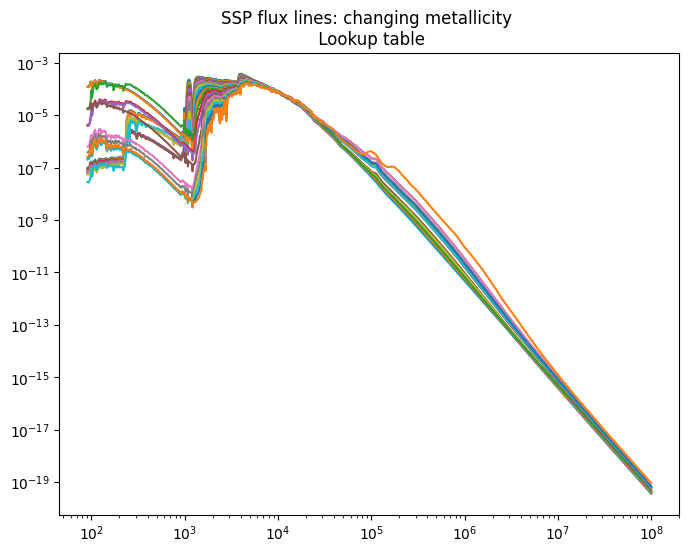

In [ ]:
#| hide

spec_flux, spec_wave = load_fsps_spectral_library()

age_fsps_gyr, Z_padova = load_fsps_age_metallicity()

plt.figure(figsize=(8, 6))

for ind0 in range(Z_padova.shape[0]):
    plt.plot(spec_wave, spec_flux[ind0, 70])
plt.xscale('log')
plt.yscale('log')
plt.title('SSP flux lines: changing metallicity \n Lookup table')

plt.show()

#### Unit check

The library is per unit solar mass *formed*, so integrating an SSP over wavelength gives its bolometric light-to-(formed-)mass ratio directly. A solar-metallicity population should fade from several hundred $L_\odot/M_\odot$ at a few Myr to below $1\,L_\odot/M_\odot$ after a few Gyr:

In [ ]:
#| hide

iz_solar = np.argmin(np.abs(Z_padova - 1.0))
for age_target in (0.005, 0.01, 0.1, 1.0, 5.0, 10.0):
    ia = np.argmin(np.abs(age_fsps_gyr - age_target))
    lbol = np.trapezoid(spec_flux[iz_solar, ia], spec_wave)
    print(f'age = {age_fsps_gyr[ia]:7.3f} Gyr   L_bol = {lbol:8.2f} Lsun per Msun formed')

# a 1 Gyr solar SSP has L_bol/M ~ 1-2 Lsun/Msun; a 10 Gyr one ~ 0.2-0.3
ia = np.argmin(np.abs(age_fsps_gyr - 1.0))
assert 0.5 < np.trapezoid(spec_flux[iz_solar, ia], spec_wave) < 3.0

age =   0.005 Gyr   L_bol =   527.56 Lsun per Msun formed
age =   0.010 Gyr   L_bol =   181.28 Lsun per Msun formed
age =   0.100 Gyr   L_bol =    11.57 Lsun per Msun formed
age =   1.000 Gyr   L_bol =     1.44 Lsun per Msun formed
age =   5.012 Gyr   L_bol =     0.47 Lsun per Msun formed
age =  10.000 Gyr   L_bol =     0.27 Lsun per Msun formed


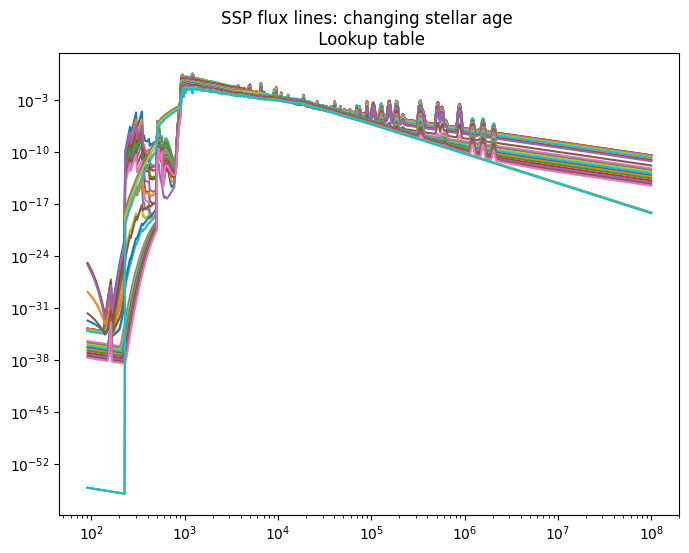

In [ ]:
#| hide

plt.figure(figsize=(8, 6))

for ind1 in range(10, 40):
    plt.plot(spec_wave, spec_flux[20, ind1])
plt.xscale('log')
plt.yscale('log')
plt.title('SSP flux lines: changing stellar age \n Lookup table')


plt.show()

In [ ]:
#| hide
import nbdev; nbdev.nbdev_export()